# Figure 7h. PPI network of ABCA1 and microglial trans-eProgram 42

STRING (v12.5, *Homo sapiens*, combined score >= 0.4) network among *ABCA1* plus the 79 genes of microglial Hotspot *trans*-eProgram 42; red edges also have physical-interaction evidence, grey edges functional association only. Only genes with at least one edge are drawn, plus *ABCA1* (red). The node layout is a seeded Fruchterman-Reingold layout, not the hand-arranged published layout.

Input: `data/Figure_7h_ABCA1_Mic_program42_PPI.rds`

In [1]:
library(ggplot2)
library(ggrepel)
ppi <- readRDS("data/Figure_7h_ABCA1_Mic_program42_PPI.rds")
## STRING v12.5, combined score >= 0.4; nodes = genes with >= 1 edge plus the focal gene
c(n_query_genes = ppi$n_query, n_nodes = nrow(ppi$nodes), n_edges = nrow(ppi$edges))
table(ppi$edges$type)
head(ppi$edges)
## trans-association ranking of program genes for the lead variant chr9:104904866:T:C
head(ppi$module_ranking, 8)

n_query_genes       n_nodes       n_edges 
           80            25            18


Functional association only     Physical-proximity link 
                         14                           4 

,gene_a,gene_b,functional_score,physical_score,type,x,y,xend,yend
,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,OSGEP,DCAKD,0.566,NA,Functional association only,-1.2302734,5.4211547,-1.9793717,4.9579357
2,OSGEP,WDR73,0.755,NA,Functional association only,-1.2302734,5.4211547,-0.5345962,5.9735126
3,PIGL,CARS2,0.691,NA,Functional association only,3.1660640,0.1710100,2.5003707,-0.4384538
4,NT5C,PDE5A,0.650,NA,Functional association only,0.2694317,0.5938926,1.0351020,1.0109908
5,CARS2,PTS,0.426,NA,Functional association only,2.5003707,-0.4384538,1.8032922,-1.0321151
6,CYSTM1,RAB11A,0.489,0.459,Physical-proximity link,2.8558120,3.6358296,3.7145589,3.3672470


,ensembl_id,gene,z,p_value,rank
,<chr>,<chr>,<dbl>,<dbl>,<int>
ENSG00000186047,ENSG00000186047,DLEU7,-2.426406,0.01524922,1
ENSG00000127990,ENSG00000127990,SGCE,-2.373566,0.01761725,2
ENSG00000132256,ENSG00000132256,TRIM5,-2.347720,0.01888872,3
ENSG00000145936,ENSG00000145936,KCNMB1,-2.333216,0.01963683,4
ENSG00000206199,ENSG00000206199,ANKUB1,-2.321639,0.02025239,5
ENSG00000079459,ENSG00000079459,FDFT1,2.237723,0.02523913,6
ENSG00000120306,ENSG00000120306,CYSTM1,-2.059453,0.03945090,7
ENSG00000204977,ENSG00000204977,TRIM13,-2.050773,0.04028906,8


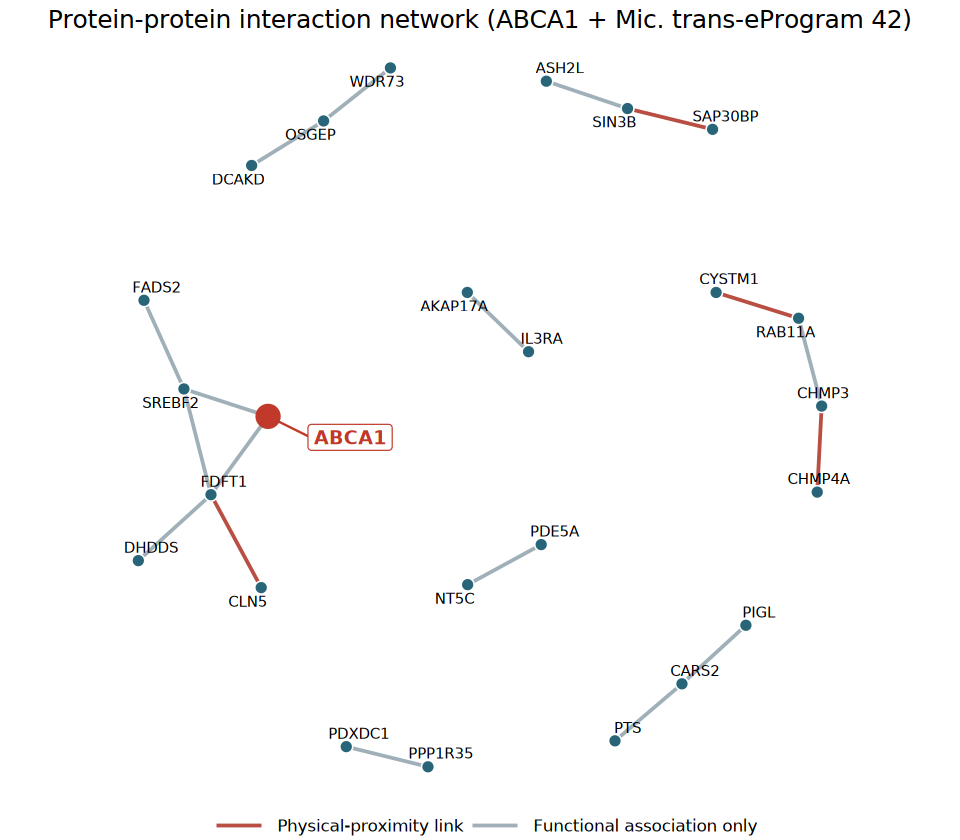

In [2]:
TITLE <- "Protein-protein interaction network (ABCA1 + Mic. trans-eProgram 42)"
FOCAL_LABEL <- "ABCA1"
NUDGE <- c(0.12, -0.03)  # label offset as a fraction of the layout range
edges <- ppi$edges
nodes <- ppi$nodes
focal <- nodes[nodes$focal, ]
focal$label <- FOCAL_LABEL

p <- ggplot() +
  geom_segment(data = edges, aes(x, y, xend = xend, yend = yend, colour = type), linewidth = 0.8) +
  geom_point(data = nodes[!nodes$focal, ], aes(x, y), shape = 21, size = 3, fill = "#286579",
             colour = "white", stroke = 0.5) +
  geom_point(data = focal, aes(x, y), size = 6, colour = "#C0392B") +
  geom_text_repel(data = nodes[!nodes$focal, ], aes(x, y, label = gene), size = 3,
                  fontface = "italic", seed = 1, max.overlaps = Inf, min.segment.length = 0.3,
                  segment.colour = "grey70") +
  geom_label_repel(data = focal, aes(x, y, label = label), size = 4, fontface = "bold",
                   colour = "#C0392B", fill = "white", label.size = NA, seed = 1,
                   nudge_x = NUDGE[1] * diff(range(nodes$x)),
                   nudge_y = NUDGE[2] * diff(range(nodes$y)), box.padding = 0.6,
                   segment.colour = "#C0392B", max.overlaps = Inf) +
  scale_colour_manual(values = c("Physical-proximity link" = "#B94F43",
                                 "Functional association only" = "#A0B0B8"),
                      breaks = c("Physical-proximity link", "Functional association only"),
                      name = NULL) +
  labs(title = TITLE) +
  coord_fixed() +
  theme_void(base_size = 12) +
  theme(plot.title = element_text(hjust = 0.5), legend.position = "bottom",
        legend.key.width = grid::unit(12, "mm"))

options(repr.plot.width = 8, repr.plot.height = 7)
p